In [1]:
import csv
import json
import math
import random
from collections import Counter
from functools import partial
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import psutil
import torch
from datasets import load_dataset
from peft import LoraConfig, TaskType, get_peft_model
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer

from data import DATASET_NAME, SEED, count_classes, prepare_data
from inference import predict
from prompts import MODEL_NAME, SYSTEM_PROMPT, build_messages, format_prompt
from training import collate_batch, prepare_example


### Загрузка и выборки


In [2]:
dataset = load_dataset(DATASET_NAME)
train_data, few_shot_data, test_data = prepare_data(dataset)

print(f"train: {len(train_data)}, few-shot: {len(few_shot_data)}, test: {len(test_data)}")


train: 5000, few-shot: 5, test: 1000


### Проверка состава



In [3]:
for example in few_shot_data:
    print(f"Оценка: {example['stars']}\n{example['text']}\n")


Оценка: 4
Ставлю за концерт 4 звёзды(((\n   Голоса шикарные, поют волшебно, единственное, что художественный руководитель, Захарченко (ему почёт и уважение), но он забрал на лекции очень много времени ((( Конечно все что он говорил правильно, но на концерт шли отдохнуть и насладиться творчеством! \nДа, и ещё! Из огромного репертуара выбрали не самые лучшие песни для первого части программы. На протяжении часа были колыбельная за колыбельной, чуть не уснули. Вообще, немного было разочарование ((( Могу сравнить Кубанский казачий хор  с бриллиантом, но без огранки.

Оценка: 3
Была именно в этом заведении, купили пончики, картошку, тирамису и десерт (киви).\nВзяли айс-кофе.\nПо бонусным программам нет вопросов, НО есть в Санкт-Петербурге аналогичные булочные и это, конечно, небо и земля.\nОсобенно хочу отметить пироженое "картошка". Честно говоря, это самая невкусная картошка в жизни.\nВ СПб это пироженное можно есть сутками, а тут откусила и выбросила остаток.\nПончики хороши. Кофе - горч

### Загрузка Qwen3-0.6B

При первом запуске скачиваются токенизатор и веса модели. Они остаются в кэше Hugging Face.

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype="auto")
model = model.to(device)
model.eval()

print(f"Модель: {MODEL_NAME}")
print(f"Устройство: {device}")
print(f"Параметров: {model.num_parameters():,}")


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Модель: Qwen/Qwen3-0.6B
Устройство: cuda
Параметров: 596,049,920


### Промпты zero-shot и few-shot


In [5]:
review = test_data[0]["text"]
zero_shot_messages = build_messages(review)
few_shot_messages  = build_messages(review, few_shot_data)

zero_shot_prompt = format_prompt(tokenizer, zero_shot_messages)
few_shot_prompt = format_prompt(tokenizer, few_shot_messages)

print("ZERO-SHOT:\n")
print(zero_shot_prompt)
print("\nFEW-SHOT:\n")
print(few_shot_prompt)


ZERO-SHOT:

<|im_start|>system
Определи оценку, которую автор поставил организации, по тексту отзыва по шкале от 1 до 5. Где 1 - плохо, а 5 - хорошо. Ответь одной цифрой от 1 до 5<|im_end|>
<|im_start|>user
Делала маникюр и педикюр в этом салоне. Салон неряшливый, видно что работникам всё равно в каких условиях принимать клиентов, да и самим работать. Но в целом услуга оказана. Но такая оценка именно мастеру. Больше к ней не пойду. Во-первых она не надела перчатки для проведения маникюра. Во вторых во время процедуры смотрела телевизор и издергала мне руки. Педикюр сделала хорошо, и в перчатках. <|im_end|>
<|im_start|>assistant
<think>

</think>



FEW-SHOT:

<|im_start|>system
Определи оценку, которую автор поставил организации, по тексту отзыва по шкале от 1 до 5. Где 1 - плохо, а 5 - хорошо. Ответь одной цифрой от 1 до 5<|im_end|>
<|im_start|>user
Ставлю за концерт 4 звёзды(((\n   Голоса шикарные, поют волшебно, единственное, что художественный руководитель, Захарченко (ему почёт и 

### Генерация и разбор ответа

Проверяем два режима на одном отзыве. Жадная генерация: `do_sample=False`, максимум три новых токена. Если оценки 1–5 нет, предсказание — `None`, ответ учитывается в `invalid`.

In [6]:
print("Отзыв:", review)
print("Правильная оценка:", test_data[0]["stars"])

results = {}
for mode, prompt in [("zero_shot", zero_shot_prompt), ("few_shot", few_shot_prompt)]:
    raw_answer, prediction = predict(model, tokenizer, prompt)
    invalid = int(prediction is None)
    results[mode] = {
        "raw_answer": raw_answer,
        "prediction": prediction,
        "invalid": invalid,
    }
    print(f"{mode}: ответ={raw_answer!r}, оценка={prediction}, invalid={invalid}")


Отзыв: Делала маникюр и педикюр в этом салоне. Салон неряшливый, видно что работникам всё равно в каких условиях принимать клиентов, да и самим работать. Но в целом услуга оказана. Но такая оценка именно мастеру. Больше к ней не пойду. Во-первых она не надела перчатки для проведения маникюра. Во вторых во время процедуры смотрела телевизор и издергала мне руки. Педикюр сделала хорошо, и в перчатках. 
Правильная оценка: 3
zero_shot: ответ='4', оценка=4, invalid=0
few_shot: ответ='2', оценка=2, invalid=0


### Настройки обучения LoRA

Следующие ячейки готовят адаптер и данные. Обучение начинается только в ячейке «Запуск обучения». После неё выполняется сохранение адаптера и артефактов. При необходимости установите `peft` командой `pip install -r requirements.txt`.

In [7]:
LORA_R = 8
LORA_ALPHA = 16
TARGET_MODULES = [ # Линейные слои внимания и полносвязной части
    "q_proj", "k_proj", "v_proj", "o_proj",
    "gate_proj", "up_proj", "down_proj",
]
EPOCHS = 1
LR = 2e-4
BATCH_SIZE = 8 # Размер батча. После него начнется обновления весов
# Размер батча за один проход модели. Можно уменьшить, если не хватает памяти.
# Обновление весов останется после BATCH_SIZE. Должно быть кратно 2-ум
MICRO_BATCH_SIZE = 8 

ACCUMULATION_STEPS = BATCH_SIZE // MICRO_BATCH_SIZE
MAX_LEN = 256
ARTIFACTS = Path("artifacts")

random.seed(SEED)
torch.manual_seed(SEED)
if device == "cuda":
    torch.cuda.manual_seed_all(SEED)


### Подключение адаптера

Базовые веса заморожены: оптимизатор будет обновлять только LoRA. Эту ячейку выполняем один раз после загрузки базовой модели.

In [8]:
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, # Тип модели - предсказывание следующего токена
    r=LORA_R, # Размерность матриц, перемножение которых дает поправку
    lora_alpha=LORA_ALPHA, # Коэффициент поправки. На alpha/r умножается произведение обучаемых матриц
    target_modules=TARGET_MODULES, # К каким слоям добавляем поправку
    bias="none", # Не обучаем параметры смещения
)

# Подключает адаптер к модели. Модель та же, но при обчении будут обновляться только параметры LoRA
model = get_peft_model(model, lora_config)
# При генерации ускоряет получение токенов, но при обучении забирает лишнюю память
model.config.use_cache = False

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad) 
total_params = sum(p.numel() for p in model.parameters())
trainable_pct = 100 * trainable_params / total_params
print(f"Обучаемых параметров: {trainable_params:,} из {total_params:,}")
print(f"Доля: {trainable_pct:.3f}%")

# Проверяем, что все обучаемые параметры относятся к LoRA
assert all("lora_" in name for name, p in model.named_parameters() if p.requires_grad)


Обучаемых параметров: 5,046,272 из 601,096,192
Доля: 0.840%


### Обучающие примеры и батчи

In [9]:
train_examples = [prepare_example(example, tokenizer, MAX_LEN) for example in train_data]

# Добавляем токен для заполнения пустых мест, что бы все батчи были одинакового размера
pad_token_id = tokenizer.pad_token_id
if pad_token_id is None:
    pad_token_id = tokenizer.eos_token_id

train_loader = DataLoader(
    train_examples,
    batch_size=MICRO_BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    collate_fn=partial(collate_batch, pad_token_id=pad_token_id),
)
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], lr=LR,
)

example = train_examples[0]
answer_tokens = [token for token in example["labels"] if token != -100]
print("Обучающих примеров:", len(train_examples))
print("Максимальная длина:", max(len(item["input_ids"]) for item in train_examples))
print("Ответ для лосса:", repr(tokenizer.decode(answer_tokens, skip_special_tokens=False)))
print("Эффективный батч:", BATCH_SIZE)
print("Шагов оптимизатора:", math.ceil(len(train_loader) / ACCUMULATION_STEPS) * EPOCHS)

# Проверяем, что в каждом примере есть хотя бы один токен, по которому считается ошибка
assert all(any(token != -100 for token in item["labels"]) for item in train_examples)


Обучающих примеров: 5000
Максимальная длина: 256
Ответ для лосса: '2<|im_end|>'
Эффективный батч: 8
Шагов оптимизатора: 625


### Запуск обучения

In [10]:
total_steps = math.ceil(len(train_loader) / ACCUMULATION_STEPS) * EPOCHS
print(f"Устройство обучения: {device}; CUDA используется: {device == 'cuda'}", flush=True)
if device == "cuda":
    print(f"Видеокарта: {torch.cuda.get_device_name(model.device)}", flush=True)
print(
    f"Примеров: {len(train_examples)}, эпох: {EPOCHS}, шагов: {total_steps}\n"
    f"Микробатч: {MICRO_BATCH_SIZE}, накопление: {ACCUMULATION_STEPS}, "
    f"эффективный батч: {BATCH_SIZE}",
    flush=True,
)

Устройство обучения: cuda; CUDA используется: True
Видеокарта: NVIDIA GeForce GTX 1660 SUPER
Примеров: 5000, эпох: 1, шагов: 625
Микробатч: 8, накопление: 1, эффективный батч: 8


In [11]:
model.train()
optimizer.zero_grad(set_to_none=True) # Устанавливает в None накопленные градиенты

# Для точных замеров
if device == "cuda":
    torch.cuda.synchronize() # Ждёт завершения текущих вычислений на GPU

    # Сбрасывает счётчик пиковой памяти GPU, чтобы измерить максимум за время обучения, 
    # а не за всё время работы ноутбука
    torch.cuda.reset_peak_memory_stats()

process = psutil.Process()
peak_memory_bytes = 0
train_log = []
step = 0
interval_loss = 0.0
interval_batches = 0
start = perf_counter() # Для замера времени обучения
 
for epoch in range(EPOCHS):
    for batch_index, batch in enumerate(train_loader):
        batch = {key: value.to(device) for key, value in batch.items()}
        # Для последней неполной группы учитываем фактическое число микробатчей.
        group_start = (batch_index // ACCUMULATION_STEPS) * ACCUMULATION_STEPS
        group_size = min(ACCUMULATION_STEPS, len(train_loader) - group_start)
        loss = model(**batch).loss # При передаче labels модель умеет сама вычислять loss
        (loss / group_size).backward()
        interval_loss += loss.item()
        interval_batches += 1

        if device == "cpu":
            memory = process.memory_info()
            peak_memory_bytes = max(peak_memory_bytes, getattr(memory, "peak_wset", memory.rss))

        end_of_group = (batch_index + 1) % ACCUMULATION_STEPS == 0
        end_of_epoch = batch_index + 1 == len(train_loader)
        if end_of_group or end_of_epoch:
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            step += 1
            if step == 1 or step % 25 == 0 or end_of_epoch:
                average_loss = interval_loss / interval_batches
                train_log.append({"step": step, "loss": average_loss})
                elapsed_minutes = (perf_counter() - start) / 60
                if device == "cuda":
                    current_memory_gb = torch.cuda.memory_allocated() / 1024 ** 3
                else:
                    current_memory_gb = process.memory_info().rss / 1024 ** 3
                print(
                    f"Эпоха {epoch + 1}/{EPOCHS} | шаг {step}/{total_steps} "
                    f"({100 * step / total_steps:.1f}%) | loss={average_loss:.4f} | "
                    f"прошло {elapsed_minutes:.2f} мин | память {current_memory_gb:.2f} ГиБ",
                    flush=True,
                )
                interval_loss = 0.0
                interval_batches = 0

if device == "cuda":
    torch.cuda.synchronize()
    peak_memory_bytes = torch.cuda.max_memory_allocated()
train_minutes = (perf_counter() - start) / 60
peak_memory_gb = peak_memory_bytes / 1024 ** 3
model.eval()
model.config.use_cache = True
print(f"Время обучения: {train_minutes:.2f} мин")
print(f"Пиковая память: {peak_memory_gb:.3f} ГиБ")


Эпоха 1/1 | шаг 1/625 (0.2%) | loss=1.3337 | прошло 0.21 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 25/625 (4.0%) | loss=0.6771 | прошло 4.86 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 50/625 (8.0%) | loss=0.5908 | прошло 9.56 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 75/625 (12.0%) | loss=0.5848 | прошло 14.36 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 100/625 (16.0%) | loss=0.5591 | прошло 19.14 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 125/625 (20.0%) | loss=0.5683 | прошло 23.95 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 150/625 (24.0%) | loss=0.5599 | прошло 28.72 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 175/625 (28.0%) | loss=0.5376 | прошло 33.41 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 200/625 (32.0%) | loss=0.5777 | прошло 38.20 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 225/625 (36.0%) | loss=0.5661 | прошло 42.93 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 250/625 (40.0%) | loss=0.5545 | прошло 47.64 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг 275/625 (44.0%) | loss=0.5118 | прошло 52.56 мин | память 1.18 ГиБ
Эпоха 1/1 | шаг

### Сохранение адаптера и результатов

Выполняется после обучения. Сохраняются только веса адаптера, базовые веса Qwen в репозиторий не добавляются.

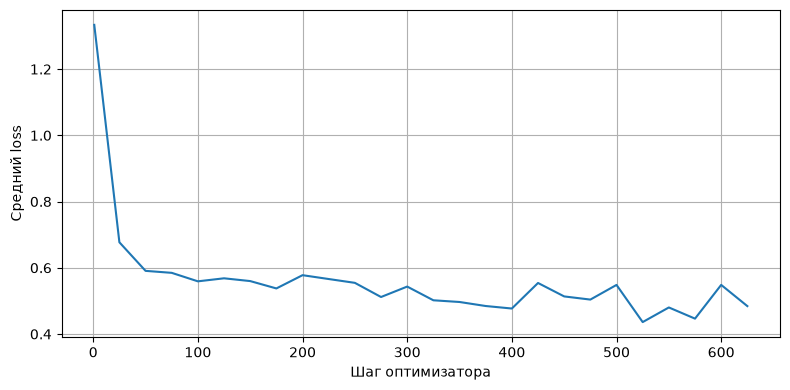

Адаптер и артефакты сохранены в C:\Projects\tgo_course\lab04\artifacts


In [13]:
ARTIFACTS.mkdir(exist_ok=True)
model.save_pretrained(ARTIFACTS / "adapter")

train_config = {
    "model": MODEL_NAME,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "target_modules": TARGET_MODULES,
    "trainable_params": trainable_params,
    "total_params": total_params,
    "trainable_pct": trainable_pct,
    "train_examples": len(train_examples),
    "epochs": EPOCHS,
    "steps": step,
    "batch": BATCH_SIZE,
    "lr": LR,
    "max_len": MAX_LEN,
    "train_minutes": train_minutes,
    "peak_memory_gb": peak_memory_gb,
    "device": device,
    "seed": SEED,
}
(ARTIFACTS / "train_config.json").write_text(
    json.dumps(train_config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
with (ARTIFACTS / "train_log.csv").open("w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["step", "loss"])
    writer.writeheader()
    writer.writerows(train_log)

plt.figure(figsize=(8, 4))
plt.plot([row["step"] for row in train_log], [row["loss"] for row in train_log])
plt.xlabel("Шаг оптимизатора")
plt.ylabel("Средний loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(ARTIFACTS / "train_loss.png")
plt.show()
print("Адаптер и артефакты сохранены в", ARTIFACTS.resolve())
